# Лабораторная работа 3

1) Полносвязная нейронная сеть ( Fully-Connected Neural Network)

2) Нормализация по мини-батчам (Batch normalization)

3) Dropout

4) Сверточные нейронные сети (Convolutional Networks)

Лабораторные работы можно выполнять с использованием сервиса Google Colaboratory (https://medium.com/deep-learning-turkey/google-colab-free-gpu-tutorial-e113627b9f5d) или на локальном компьютере. 

# Полносвязная нейронная сеть

В данной лабораторной работе необходимо будет реализовать полносвязную нейронную сеть, используя модульный подход. Для каждого  слоя реализации прямого и обратного проходов алгоритма обратного распространения ошибки будут иметь следующий вид:

```python
def layer_forward(x, w):
  """ Receive inputs x and weights w """
  # Do some computations ...
  z = # ... some intermediate value
  # Do some more computations ...
  out = # the output
   
  cache = (x, w, z, out) # Values we need to compute gradients
   
  return out, cache
```



```python
def layer_backward(dout, cache):
  """
  Receive dout (derivative of loss with respect to outputs) and cache,
  and compute derivative with respect to inputs.
  """
  # Unpack cache values
  x, w, z, out = cache
  
  # Use values in cache to compute derivatives
  dx = # Derivative of loss with respect to x
  dw = # Derivative of loss with respect to w
  
  return dx, dw
```

    

In [1]:
from __future__ import print_function
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from threadpoolctl import threadpool_limits

from scripts.classifiers.fc_net import *
from scripts.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from scripts.solver import Solver
from scripts.classifiers.cnn import *
from scripts.layers import *
from scripts.fast_layers import *
from IPython.display import display, Markdown

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

%load_ext autoreload
%autoreload 2

np.random.seed(42)
_blas_limit = threadpool_limits(limits=1)
checks = {}

def rel_error(x, y):
    return np.max(np.abs(x - y) / np.maximum(1e-8, np.abs(x) + np.abs(y)))


def print_mean_std(x, axis=0):
    print('Средние:', x.mean(axis=axis))
    print('Стандартные отклонения:', x.std(axis=axis))
    print()


def verify(name, actual, expected, tolerance=1e-6):
    error = float(rel_error(actual, expected))
    checks[name] = error
    print(f'{name}: {error:.2e}')
    assert np.allclose(actual, expected, rtol=tolerance, atol=1e-9), name
    return error

Загрузите данные из предыдущей лабораторной работы. 

In [2]:
digits = load_digits()
X = digits.data.astype(np.float64)
y = digits.target.astype(np.int64)
images = digits.images.astype(np.float32) / 16.0

X_train_raw, X_test_raw, y_train, y_test, img_train, img_test = train_test_split(
    X, y, images, test_size=0.20, stratify=y, random_state=42
)
X_train_raw, X_val_raw, y_train, y_val, img_train, img_val = train_test_split(
    X_train_raw, y_train, img_train, test_size=0.20, stratify=y_train, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_val = scaler.transform(X_val_raw).astype(np.float32)
X_test = scaler.transform(X_test_raw).astype(np.float32)

X_train_cnn = img_train[:, None, :, :]
X_val_cnn = img_val[:, None, :, :]
X_test_cnn = img_test[:, None, :, :]

data = {
    'X_train': X_train,
    'y_train': y_train,
    'X_val': X_val,
    'y_val': y_val,
}
cnn_data = {
    'X_train': X_train_cnn,
    'y_train': y_train,
    'X_val': X_val_cnn,
    'y_val': y_val,
}

print('Train:', X_train.shape, X_train_cnn.shape)
print('Validation:', X_val.shape, X_val_cnn.shape)
print('Test:', X_test.shape, X_test_cnn.shape)

data.update(X_test=X_test, y_test=y_test)
cnn_data.update(X_test=X_test_cnn, y_test=y_test)
input_dim = X_train.shape[1]
num_classes = len(np.unique(y_train))
print('Вариант 4: Digits 8×8, load_digits(), как в предыдущей работе; это не MNIST 28×28.')

Train: (1149, 64) (1149, 1, 8, 8)
Validation: (288, 64) (288, 1, 8, 8)
Test: (360, 64) (360, 1, 8, 8)
Вариант 4: Digits 8×8, load_digits(), как в предыдущей работе; это не MNIST 28×28.


Для полносвязного слоя реализуйте прямой проход (метод affine_forward в scripts/layers.py). Протестируйте свою реализацию. 

In [3]:
num_inputs = 2
input_shape = (4, 5, 6)
output_dim = 3
input_size = num_inputs * np.prod(input_shape)
weight_size = output_dim * np.prod(input_shape)
x = np.linspace(-0.1, 0.5, num=input_size).reshape(num_inputs, *input_shape)
w = np.linspace(-0.2, 0.3, num=weight_size).reshape(np.prod(input_shape), output_dim)
b = np.linspace(-0.3, 0.1, num=output_dim)
out, _ = affine_forward(x, w, b)
correct_out = np.array([[1.49834967, 1.70660132, 1.91485297],
                        [3.25553199, 3.5141327, 3.77273342]])
verify('affine_forward', out, correct_out)

affine_forward: 9.77e-10


9.769848888397517e-10

Для полносвязного слоя реализуйте обратный проход (метод affine_backward в scripts/layers.py). Протестируйте свою реализацию. 

In [4]:
np.random.seed(231)
x = np.random.randn(10, 2, 3)
w = np.random.randn(6, 5)
b = np.random.randn(5)
dout = np.random.randn(10, 5)
dx_num = eval_numerical_gradient_array(lambda x: affine_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_forward(x, w, b)[0], b, dout)
_, cache = affine_forward(x, w, b)
dx, dw, db = affine_backward(dout, cache)
verify('affine_backward dx', dx, dx_num)
verify('affine_backward dw', dw, dw_num)
verify('affine_backward db', db, db_num)

affine_backward dx: 5.40e-11
affine_backward dw: 9.90e-11
affine_backward db: 2.41e-11


2.4122867568119087e-11

Реализуйте прямой проход для слоя активации ReLU (relu_forward) и протестируйте его.

In [5]:
x = np.linspace(-0.5, 0.5, num=12).reshape(3, 4)
out, _ = relu_forward(x)
correct_out = np.array([[0., 0., 0., 0.],
                        [0., 0., 0.04545455, 0.13636364],
                        [0.22727273, 0.31818182, 0.40909091, 0.5]])
verify('relu_forward', out, correct_out)

relu_forward: 5.00e-08


4.999999798022158e-08

Реализуйте обратный проход для слоя активации ReLU (relu_backward ) и протестируйте его.

In [6]:
np.random.seed(231)
x = np.random.randn(10, 10)
dout = np.random.randn(*x.shape)
dx_num = eval_numerical_gradient_array(lambda x: relu_forward(x)[0], x, dout)
_, cache = relu_forward(x)
dx = relu_backward(dout, cache)
verify('relu_backward', dx, dx_num)

relu_backward: 3.28e-12


3.2756349136310288e-12

В скрипте /layer_utils.py приведены реализации прямого и обратного проходов для часто используемых комбинаций слоев. Например, за полносвязным слоем часто следует слой активации. Ознакомьтесь с функциями affine_relu_forward и affine_relu_backward, запустите код ниже и убедитесь, что ошибка порядка e-10 или ниже. 

In [7]:
from scripts.layer_utils import affine_relu_forward, affine_relu_backward
np.random.seed(231)
x = np.random.randn(2, 3, 4)
w = np.random.randn(12, 10)
b = np.random.randn(10)
dout = np.random.randn(2, 10)
out, cache = affine_relu_forward(x, w, b)
dx, dw, db = affine_relu_backward(dout, cache)
dx_num = eval_numerical_gradient_array(lambda x: affine_relu_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_relu_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_relu_forward(x, w, b)[0], b, dout)
verify('affine_relu dx', dx, dx_num)
verify('affine_relu dw', dw, dw_num)
verify('affine_relu db', db, db_num)

affine_relu dx: 2.30e-11
affine_relu dw: 8.16e-11
affine_relu db: 7.83e-12


7.826724021458994e-12

Реализуйте двухслойную полносвязную сеть - класс TwoLayerNet в scripts/classifiers/fc_net.py . Проверьте свою реализацию, запустив код ниже. 

In [8]:
np.random.seed(231)
N, D, H, C = 3, 5, 50, 7
X = np.random.randn(N, D)
y = np.random.randint(C, size=N)
std = 1e-3
model = TwoLayerNet(input_dim=D, hidden_dim=H, num_classes=C, weight_scale=std)
assert abs(model.params['W1'].std() - std) < std / 10
assert abs(model.params['W2'].std() - std) < std / 10
assert np.all(model.params['b1'] == 0)
assert np.all(model.params['b2'] == 0)

model.params['W1'] = np.linspace(-0.7, 0.3, num=D*H).reshape(D, H)
model.params['b1'] = np.linspace(-0.1, 0.9, num=H)
model.params['W2'] = np.linspace(-0.3, 0.4, num=H*C).reshape(H, C)
model.params['b2'] = np.linspace(-0.9, 0.1, num=C)
X = np.linspace(-5.5, 4.5, num=N*D).reshape(D, N).T
scores = model.loss(X)
correct_scores = np.asarray([
    [11.53165108, 12.2917344, 13.05181771, 13.81190102, 14.57198434, 15.33206765, 16.09215096],
    [12.05769098, 12.74614105, 13.43459113, 14.1230412, 14.81149128, 15.49994135, 16.18839143],
    [12.58373087, 13.20054771, 13.81736455, 14.43418138, 15.05099822, 15.66781506, 16.2846319]])
assert np.abs(scores - correct_scores).sum() < 1e-6
y = np.asarray([0, 5, 1])
loss, grads = model.loss(X, y)
assert abs(loss - 3.4702243556) < 1e-10
model.reg = 1.0
loss, grads = model.loss(X, y)
assert abs(loss - 26.5948426952) < 1e-10
print('Инициализация, прямой проход и регуляризация: проверки пройдены.')

for reg in [0.0, 0.7]:
    model.reg = reg
    loss, grads = model.loss(X, y)
    for name in sorted(grads):
        grad_num = eval_numerical_gradient(lambda _: model.loss(X, y)[0], model.params[name], verbose=False)
        verify(f'TwoLayerNet reg={reg} {name}', grads[name], grad_num)

Инициализация, прямой проход и регуляризация: проверки пройдены.
TwoLayerNet reg=0.0 W1: 1.52e-08
TwoLayerNet reg=0.0 W2: 3.21e-10
TwoLayerNet reg=0.0 b1: 8.37e-09
TwoLayerNet reg=0.0 b2: 4.33e-10


TwoLayerNet reg=0.7 W1: 2.53e-07


TwoLayerNet reg=0.7 W2: 2.85e-08


TwoLayerNet reg=0.7 b1: 1.56e-08
TwoLayerNet reg=0.7 b2: 7.76e-10


Ознакомьтесь с API для обучения и тестирования моделей в scripts/solver.py . Используйте экземпляр класса Solver для обучения двухслойной полносвязной сети. Необходимо достичь минимум 50% верно классифицированных объектов на валидационном наборе. 

In [9]:
np.random.seed(42)
model = TwoLayerNet(input_dim=input_dim, hidden_dim=100, num_classes=10,
                    weight_scale=0.05, reg=1e-4)
solver = Solver(model, data, update_rule='adam',
                optim_config={'learning_rate': 1e-3},
                num_epochs=15, batch_size=64)
solver.train()
two_solver = solver
print(f'Точность на валидации: {solver.best_val_acc:.4f}')
assert solver.best_val_acc >= 0.50

Точность на валидации: 0.9688


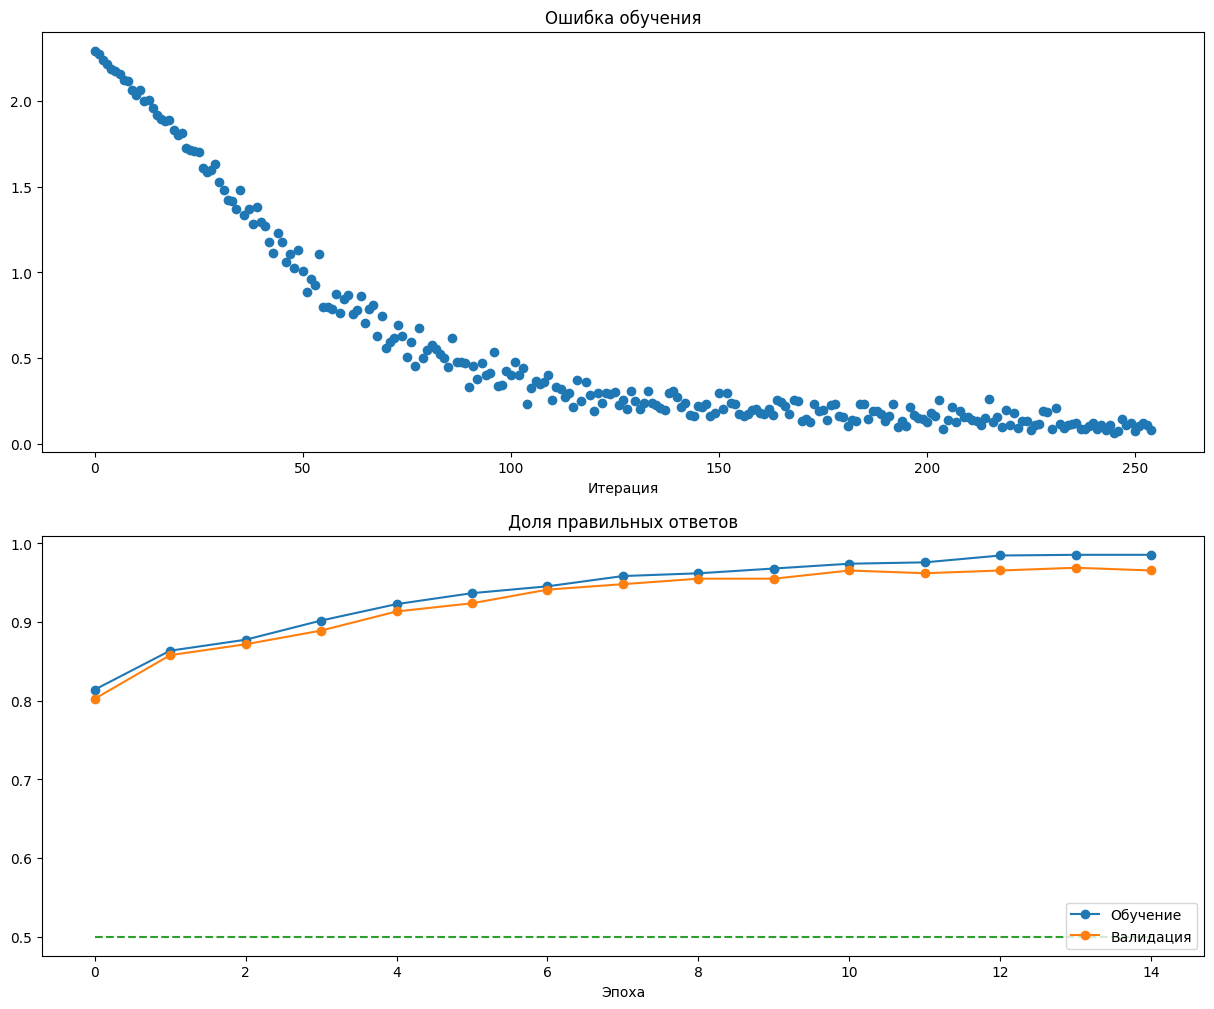

In [10]:
plt.subplot(2, 1, 1)
plt.title('Ошибка обучения')
plt.plot(solver.loss_history, 'o')
plt.xlabel('Итерация')
plt.subplot(2, 1, 2)
plt.title('Доля правильных ответов')
plt.plot(solver.train_acc_history, '-o', label='Обучение')
plt.plot(solver.val_acc_history, '-o', label='Валидация')
plt.plot([0.5] * len(solver.val_acc_history), '--')
plt.xlabel('Эпоха')
plt.legend(loc='lower right')
plt.gcf().set_size_inches(15, 12)
plt.show()

Теперь реализуйте полносвязную сеть с произвольным числом скрытых слоев. Ознакомьтесь с классом FullyConnectedNet в scripts/classifiers/fc_net.py . Реализуйте инициализацию, прямой и обратный проходы.

In [11]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=N)
for reg in [0, 3.14]:
    model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                              reg=reg, weight_scale=5e-2, dtype=np.float64)
    loss, grads = model.loss(X, y)
    print(f'Регуляризация: {reg}; начальная ошибка: {loss:.6f}')
    for name in sorted(grads):
        grad_num = eval_numerical_gradient(lambda _: model.loss(X, y)[0], model.params[name], verbose=False)
        verify(f'FullyConnectedNet reg={reg} {name}', grads[name], grad_num, 1e-4)

Регуляризация: 0; начальная ошибка: 2.300479
FullyConnectedNet reg=0 W1: 1.48e-07
FullyConnectedNet reg=0 W2: 2.21e-05
FullyConnectedNet reg=0 W3: 3.53e-07
FullyConnectedNet reg=0 b1: 5.38e-09
FullyConnectedNet reg=0 b2: 2.09e-09
FullyConnectedNet reg=0 b3: 5.80e-11
Регуляризация: 3.14; начальная ошибка: 7.052115


FullyConnectedNet reg=3.14 W1: 3.90e-09
FullyConnectedNet reg=3.14 W2: 6.87e-08
FullyConnectedNet reg=3.14 W3: 2.13e-08
FullyConnectedNet reg=3.14 b1: 1.48e-08
FullyConnectedNet reg=3.14 b2: 1.72e-09
FullyConnectedNet reg=3.14 b3: 1.57e-10


Попробуйте добиться эффекта переобучения на небольшом наборе изображений (например, 50). Используйте трехслойную сеть со 100 нейронами на каждом скрытом слое. Попробуйте переобучить сеть, достигнув 100 % accuracy за 20 эпох. Для этого поэкспериментируйте с параметрами weight_scale и learning_rate. 

Точность на 50 обучающих изображениях: 1.0
Точность на отдельной валидации: 0.7777777777777778


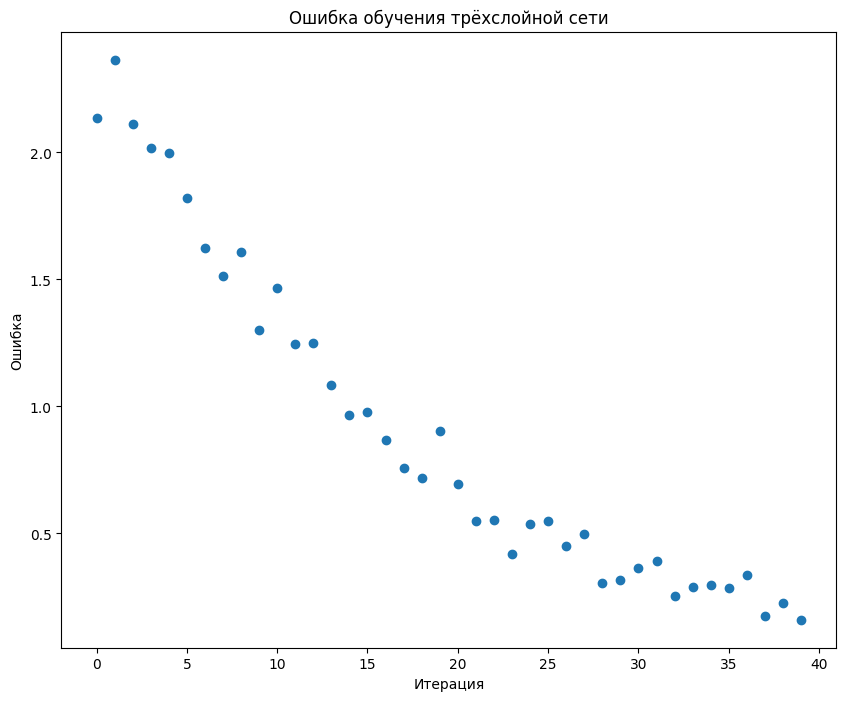

In [12]:
num_train = 50
small_data = {
    'X_train': data['X_train'][:num_train], 'y_train': data['y_train'][:num_train],
    'X_val': data['X_val'], 'y_val': data['y_val'],
}
np.random.seed(42)
weight_scale, learning_rate = 0.10, 0.10
model = FullyConnectedNet([100, 100], input_dim=input_dim,
                          weight_scale=weight_scale, dtype=np.float64)
solver = Solver(model, small_data, print_every=10, num_epochs=20, batch_size=25,
                update_rule='sgd', optim_config={'learning_rate': learning_rate},
                restore_best=False)
solver.train()
overfit_three = solver
print('Точность на 50 обучающих изображениях:', solver.check_accuracy(small_data['X_train'], small_data['y_train']))
print('Точность на отдельной валидации:', solver.check_accuracy(data['X_val'], data['y_val']))
plt.plot(solver.loss_history, 'o')
plt.title('Ошибка обучения трёхслойной сети')
plt.xlabel('Итерация')
plt.ylabel('Ошибка')
plt.show()

Повторите эксперимент, описанный выше, для пятислойной сети.

Точность на 50 обучающих изображениях: 1.0
Точность на отдельной валидации: 0.7013888888888888


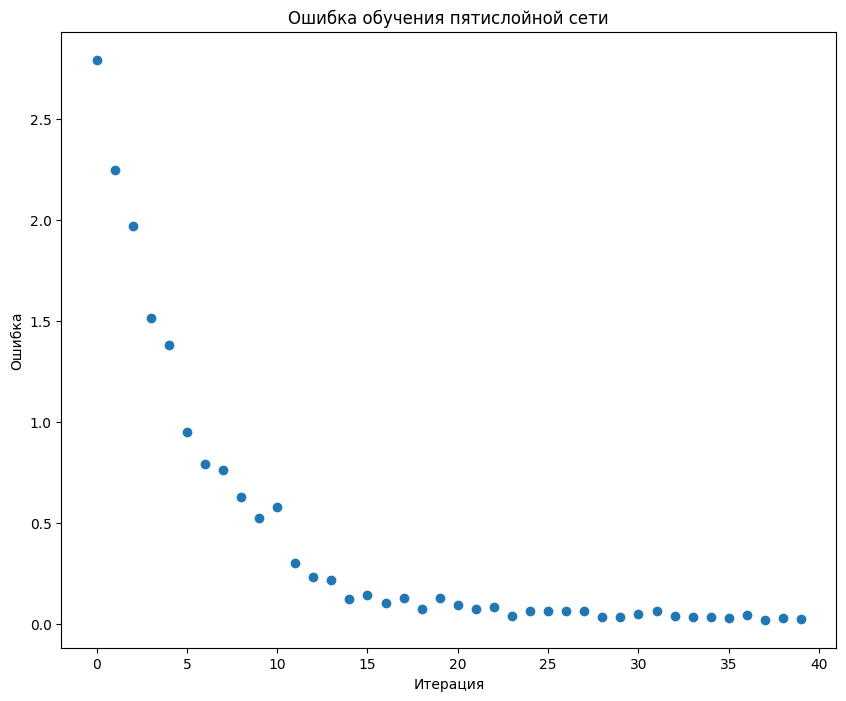

Вывод: за 20 эпох точность на 50 обучающих изображениях составила 100.0% у трёхслойной сети и 100.0% у пятислойной. Высокая точность на этой малой выборке показывает запоминание примеров; способность к обобщению оценивается отдельно на валидации.

In [13]:
np.random.seed(42)
weight_scale, learning_rate = 0.15, 0.10
model = FullyConnectedNet([100, 100, 100, 100], input_dim=input_dim,
                          weight_scale=weight_scale, dtype=np.float64)
solver = Solver(model, small_data, print_every=10, num_epochs=20, batch_size=25,
                update_rule='sgd', optim_config={'learning_rate': learning_rate},
                restore_best=False)
solver.train()
overfit_five = solver
print('Точность на 50 обучающих изображениях:', solver.check_accuracy(small_data['X_train'], small_data['y_train']))
print('Точность на отдельной валидации:', solver.check_accuracy(data['X_val'], data['y_val']))
plt.plot(solver.loss_history, 'o')
plt.title('Ошибка обучения пятислойной сети')
plt.xlabel('Итерация')
plt.ylabel('Ошибка')
plt.show()
a3 = overfit_three.check_accuracy(small_data['X_train'], small_data['y_train'])
a5 = overfit_five.check_accuracy(small_data['X_train'], small_data['y_train'])
display(Markdown(f'Вывод: за 20 эпох точность на 50 обучающих изображениях составила '
                 f'{a3:.1%} у трёхслойной сети и {a5:.1%} у пятислойной. '
                 'Высокая точность на этой малой выборке показывает запоминание примеров; '
                 'способность к обобщению оценивается отдельно на валидации.'))

Сделайте выводы по проведенному эксперименту. 

Ранее обновление весов проходило по правилу SGD. Теперь попробуйте реализовать стохастический градиентный спуск с импульсом (SGD+momentum). http://cs231n.github.io/neural-networks-3/#sgd Реализуйте sgd_momentum в scripts/optim.py  и запустите проверку. 

In [14]:
from scripts.optim import sgd_momentum
N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
v = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)
config = {'learning_rate': 1e-3, 'velocity': v}
next_w, _ = sgd_momentum(w, dw, config=config)
expected_next_w = np.asarray([
    [0.1406, 0.20738947, 0.27417895, 0.34096842, 0.40775789],
    [0.47454737, 0.54133684, 0.60812632, 0.67491579, 0.74170526],
    [0.80849474, 0.87528421, 0.94207368, 1.00886316, 1.07565263],
    [1.14244211, 1.20923158, 1.27602105, 1.34281053, 1.4096]])
expected_velocity = np.asarray([
    [0.5406, 0.55475789, 0.56891579, 0.58307368, 0.59723158],
    [0.61138947, 0.62554737, 0.63970526, 0.65386316, 0.66802105],
    [0.68217895, 0.69633684, 0.71049474, 0.72465263, 0.73881053],
    [0.75296842, 0.76712632, 0.78128421, 0.79544211, 0.8096]])
verify('Momentum: веса', next_w, expected_next_w)
verify('Momentum: скорость', config['velocity'], expected_velocity)

Momentum: веса: 8.88e-09
Momentum: скорость: 4.27e-09


4.269287743278663e-09

Сравните результаты обучения шестислойной сети, обученной классическим градиентным спуском и адаптивным алгоритмом с импульсом. Какой алгоритм сходится быстрее.

sgd лучшая точность на валидации: 0.46875


sgd_momentum лучшая точность на валидации: 0.9270833333333334


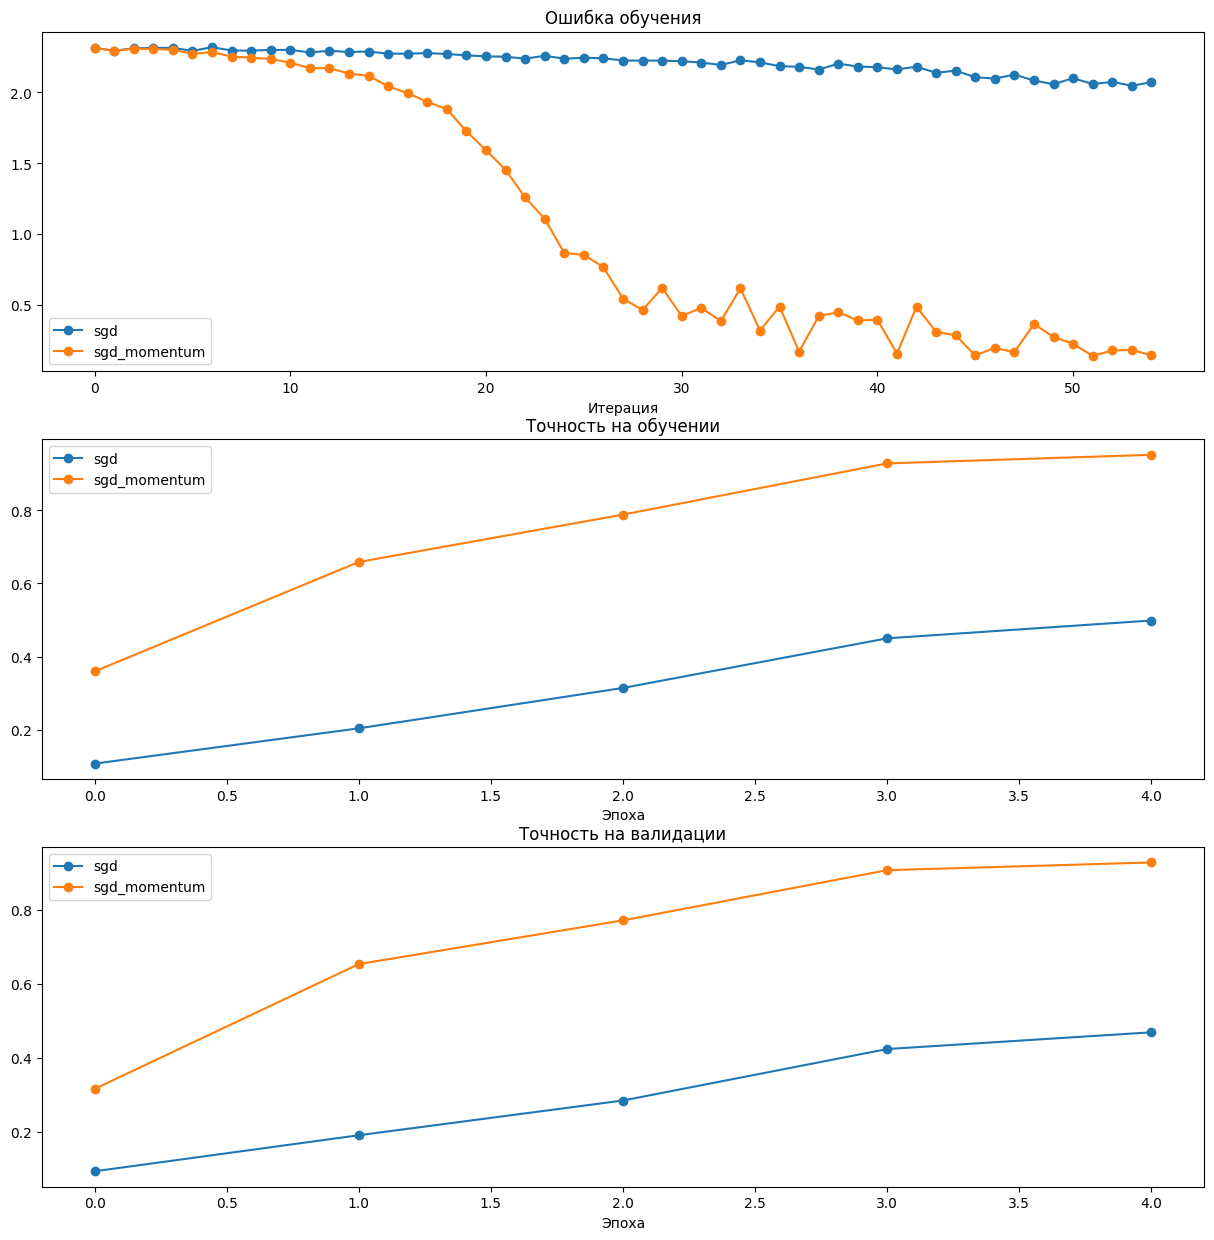

После пяти эпох выше точность у sgd_momentum. Сравнение выполнено с одинаковой инициализацией и скоростью обучения.


In [15]:
num_train = min(4000, len(data['X_train']))
small_data = {
    'X_train': data['X_train'][:num_train], 'y_train': data['y_train'][:num_train],
    'X_val': data['X_val'], 'y_val': data['y_val'],
}
solvers = {}
for update_rule in ['sgd', 'sgd_momentum']:
    np.random.seed(42)
    model = FullyConnectedNet([100, 100, 100, 100, 100], input_dim=input_dim, weight_scale=0.10)
    solver = Solver(model, small_data, num_epochs=5, batch_size=100,
                    update_rule=update_rule, optim_config={'learning_rate': 0.05})
    solver.train()
    solvers[update_rule] = solver
    print(update_rule, 'лучшая точность на валидации:', solver.best_val_acc)

for i, (field, title, xlabel) in enumerate([
    ('loss_history', 'Ошибка обучения', 'Итерация'),
    ('train_acc_history', 'Точность на обучении', 'Эпоха'),
    ('val_acc_history', 'Точность на валидации', 'Эпоха'),
], start=1):
    plt.subplot(3, 1, i)
    for rule, solver in solvers.items():
        plt.plot(getattr(solver, field), '-o', label=rule)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.legend()
plt.gcf().set_size_inches(15, 15)
plt.show()
optimizer_results = dict(solvers)
faster = max(solvers, key=lambda key: solvers[key].val_acc_history[-1])
print(f'После пяти эпох выше точность у {faster}. Сравнение выполнено с одинаковой инициализацией и скоростью обучения.')

Реализуйте алгоритмы RMSProp [1] and Adam [2] с коррекцией смещения  - методы rmsprop и adam . 


[1] Tijmen Tieleman and Geoffrey Hinton. "Lecture 6.5-rmsprop: Divide the gradient by a running average of its recent magnitude." COURSERA: Neural Networks for Machine Learning 4 (2012).

[2] Diederik Kingma and Jimmy Ba, "Adam: A Method for Stochastic Optimization", ICLR 2015.

In [16]:
from scripts.optim import rmsprop
N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
cache = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)
config = {'learning_rate': 1e-2, 'cache': cache}
next_w, _ = rmsprop(w, dw, config=config)
expected_next_w = np.asarray([
    [-0.39223849, -0.34037513, -0.28849239, -0.23659121, -0.18467247],
    [-0.132737, -0.08078555, -0.02881884, 0.02316247, 0.07515774],
    [0.12716641, 0.17918792, 0.23122175, 0.28326742, 0.33532447],
    [0.38739248, 0.43947102, 0.49155973, 0.54365823, 0.59576619]])
expected_cache = np.asarray([
    [0.5976, 0.6126277, 0.6277108, 0.64284931, 0.65804321],
    [0.67329252, 0.68859723, 0.70395734, 0.71937285, 0.73484377],
    [0.75037008, 0.7659518, 0.78158892, 0.79728144, 0.81302936],
    [0.82883269, 0.84469141, 0.86060554, 0.87657507, 0.8926]])
verify('RMSProp: веса', next_w, expected_next_w)
verify('RMSProp: накопленные квадраты', config['cache'], expected_cache)

RMSProp: веса: 9.52e-08
RMSProp: накопленные квадраты: 2.65e-09


2.6477955807156126e-09

In [17]:
from scripts.optim import adam
N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
m = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)
v = np.linspace(0.7, 0.5, num=N*D).reshape(N, D)
config = {'learning_rate': 1e-2, 'm': m, 'v': v, 't': 5}
next_w, _ = adam(w, dw, config=config)
expected_next_w = np.asarray([
    [-0.40094747, -0.34836187, -0.29577703, -0.24319299, -0.19060977],
    [-0.1380274, -0.08544591, -0.03286534, 0.01971428, 0.0722929],
    [0.1248705, 0.17744702, 0.23002243, 0.28259667, 0.33516969],
    [0.38774145, 0.44031188, 0.49288093, 0.54544852, 0.59801459]])
expected_v = np.asarray([
    [0.69966, 0.68908382, 0.67851319, 0.66794809, 0.65738853],
    [0.64683452, 0.63628604, 0.6257431, 0.61520571, 0.60467385],
    [0.59414753, 0.58362676, 0.57311152, 0.56260183, 0.55209767],
    [0.54159906, 0.53110598, 0.52061845, 0.51013645, 0.49966]])
expected_m = np.asarray([
    [0.48, 0.49947368, 0.51894737, 0.53842105, 0.55789474],
    [0.57736842, 0.59684211, 0.61631579, 0.63578947, 0.65526316],
    [0.67473684, 0.69421053, 0.71368421, 0.73315789, 0.75263158],
    [0.77210526, 0.79157895, 0.81105263, 0.83052632, 0.85]])
verify('Adam: веса', next_w, expected_next_w)
verify('Adam: второй момент', config['v'], expected_v)
verify('Adam: первый момент', config['m'], expected_m)

Adam: веса: 1.14e-07
Adam: второй момент: 4.21e-09
Adam: первый момент: 4.21e-09


4.214963193114416e-09

Обучите пару глубоких сетей с испольованием RMSProp и Adam алгоритмов обновления весов и сравните результаты обучения.

Получите лучшую полносвязную сеть для классификации вашего набора данных. На наборе CIFAR-10 необходимо получить accuracy не ниже 50 % на валидационном наборе.

rmsprop лучшая точность на валидации: 0.9722222222222222


adam лучшая точность на валидации: 0.9652777777777778


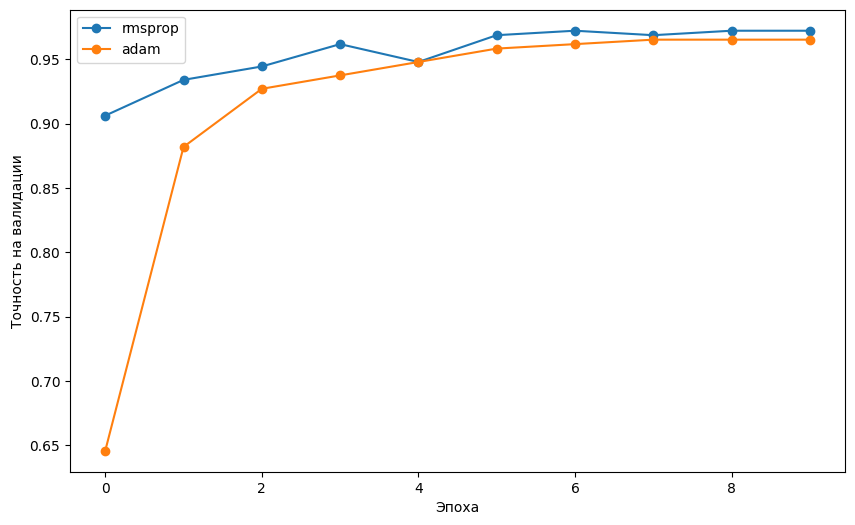

В данном запуске выше лучшая точность у rmsprop


Настроенная полносвязная сеть, валидация: 0.9930555555555556


In [18]:
for update_rule in ['rmsprop', 'adam']:
    np.random.seed(42)
    model = FullyConnectedNet([100, 100, 100, 100, 100], input_dim=input_dim, weight_scale=0.10)
    solver = Solver(model, data, update_rule=update_rule,
                    optim_config={'learning_rate': 1e-3}, num_epochs=10, batch_size=64)
    solver.train()
    optimizer_results[update_rule] = solver
    print(update_rule, 'лучшая точность на валидации:', solver.best_val_acc)

plt.figure(figsize=(10, 6))
for update_rule in ['rmsprop', 'adam']:
    plt.plot(optimizer_results[update_rule].val_acc_history, '-o', label=update_rule)
plt.xlabel('Эпоха')
plt.ylabel('Точность на валидации')
plt.legend()
plt.show()
print('В данном запуске выше лучшая точность у', max(
    ['rmsprop', 'adam'], key=lambda rule: optimizer_results[rule].best_val_acc))

np.random.seed(42)
best_model = FullyConnectedNet([128, 64], input_dim=input_dim, num_classes=10,
                               normalization='batchnorm', weight_scale=0.05, reg=1e-4)
best_solver = Solver(best_model, data, update_rule='adam',
                     optim_config={'learning_rate': 1e-3}, num_epochs=30, batch_size=64)
best_solver.train()
print('Настроенная полносвязная сеть, валидация:', best_solver.best_val_acc)
assert best_solver.best_val_acc >= 0.50

Получите оценку accuracy для валидационной и тестовой выборок. 

In [19]:
y_test_pred = np.argmax(best_model.loss(data['X_test']), axis=1)
y_val_pred = np.argmax(best_model.loss(data['X_val']), axis=1)
fc_val_accuracy = float(np.mean(y_val_pred == data['y_val']))
fc_test_accuracy = float(np.mean(y_test_pred == data['y_test']))
print('Точность на валидации:', fc_val_accuracy)
print('Точность на тесте:', fc_test_accuracy)
best_fc = best_model

Точность на валидации: 0.9930555555555556
Точность на тесте: 0.9861111111111112


# Нормализация по мини-батчам

Идея нормализации по мини-батчам предложена в работе [1]

[1] Sergey Ioffe and Christian Szegedy, "Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift", ICML 2015.

Реализуйте прямой проход для слоя батч-нормализации - функция batchnorm_forward в scripts/layers.py . Проверьте свою реализацию, запустив следующий код:

In [20]:
np.random.seed(231)
N, D1, D2, D3 = 200, 50, 60, 3
X = np.random.randn(N, D1)
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)
a = np.maximum(0, X.dot(W1)).dot(W2)
print('До нормализации:')
print_mean_std(a, axis=0)

gamma = np.ones(D3)
beta = np.zeros(D3)
a_norm, _ = batchnorm_forward(a, gamma, beta, {'mode': 'train'})
print('После нормализации, gamma=1, beta=0:')
print_mean_std(a_norm, axis=0)
assert np.allclose(a_norm.mean(axis=0), 0, atol=1e-10)
assert np.allclose(a_norm.std(axis=0), 1, atol=1e-6)

gamma = np.asarray([1.0, 2.0, 3.0])
beta = np.asarray([11.0, 12.0, 13.0])
a_norm, _ = batchnorm_forward(a, gamma, beta, {'mode': 'train'})
print('После нормализации с заданными gamma и beta:')
print_mean_std(a_norm, axis=0)
assert np.allclose(a_norm.mean(axis=0), beta)
assert np.allclose(a_norm.std(axis=0), gamma, atol=1e-6)

До нормализации:
Средние: [ -2.3814598  -13.18038246   1.91780462]
Стандартные отклонения: [27.18502186 34.21455511 37.68611762]

После нормализации, gamma=1, beta=0:
Средние: [ 3.77475828e-17  1.70419234e-16 -3.53883589e-17]
Стандартные отклонения: [0.99999999 1.         1.        ]

После нормализации с заданными gamma и beta:
Средние: [11. 12. 13.]
Стандартные отклонения: [0.99999999 1.99999999 2.99999999]



In [21]:
np.random.seed(231)
N, D1, D2, D3 = 200, 50, 60, 3
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)
bn_param = {'mode': 'train'}
gamma = np.ones(D3)
beta = np.zeros(D3)
for t in range(50):
    X = np.random.randn(N, D1)
    a = np.maximum(0, X.dot(W1)).dot(W2)
    batchnorm_forward(a, gamma, beta, bn_param)

bn_param['mode'] = 'test'
X = np.random.randn(N, D1)
a = np.maximum(0, X.dot(W1)).dot(W2)
a_norm, _ = batchnorm_forward(a, gamma, beta, bn_param)
print('Нормализация при тестировании по накопленной статистике:')
print_mean_std(a_norm, axis=0)

Нормализация при тестировании по накопленной статистике:
Средние: [-0.03927354 -0.04349152 -0.10452688]
Стандартные отклонения: [1.01531428 1.01238373 0.97819988]



Реализуйте обратный проход в функции batchnorm_backward.

In [22]:
np.random.seed(231)
N, D = 4, 5
x = 5 * np.random.randn(N, D) + 12
gamma = np.random.randn(D)
beta = np.random.randn(D)
dout = np.random.randn(N, D)
bn_param = {'mode': 'train'}
fx = lambda x: batchnorm_forward(x, gamma, beta, bn_param)[0]
fg = lambda a: batchnorm_forward(x, a, beta, bn_param)[0]
fb = lambda b: batchnorm_forward(x, gamma, b, bn_param)[0]
dx_num = eval_numerical_gradient_array(fx, x, dout)
da_num = eval_numerical_gradient_array(fg, gamma.copy(), dout)
db_num = eval_numerical_gradient_array(fb, beta.copy(), dout)
_, cache = batchnorm_forward(x, gamma, beta, bn_param)
dx, dgamma, dbeta = batchnorm_backward(dout, cache)
verify('BatchNorm dx', dx, dx_num)
verify('BatchNorm dgamma', dgamma, da_num)
verify('BatchNorm dbeta', dbeta, db_num)

BatchNorm dx: 1.67e-09
BatchNorm dgamma: 7.42e-13
BatchNorm dbeta: 2.38e-12


2.379446949959628e-12

Измените реализацию класса FullyConnectedNet, добавив батч-нормализацию. 
Если флаг normalization == "batchnorm", то вам необходимо вставить слой батч-нормализации перед каждым слоем активации ReLU, кроме выхода сети. 

In [23]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=N)
for reg in [0, 3.14]:
    model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C, reg=reg,
                              weight_scale=5e-2, dtype=np.float64, normalization='batchnorm')
    loss, grads = model.loss(X, y)
    print(f'Регуляризация: {reg}; начальная ошибка: {loss:.6f}')
    for name in sorted(grads):
        grad_num = eval_numerical_gradient(lambda _: model.loss(X, y)[0], model.params[name], verbose=False, h=1e-5)
        verify(f'FC+BatchNorm reg={reg} {name}', grads[name], grad_num, 1e-3)

Регуляризация: 0; начальная ошибка: 2.261196


FC+BatchNorm reg=0 W1: 1.10e-04


FC+BatchNorm reg=0 W2: 3.11e-06


FC+BatchNorm reg=0 W3: 3.92e-10
FC+BatchNorm reg=0 b1: 3.11e-07
FC+BatchNorm reg=0 b2: 2.72e-07
FC+BatchNorm reg=0 b3: 1.01e-10
FC+BatchNorm reg=0 beta1: 7.33e-09
FC+BatchNorm reg=0 beta2: 1.89e-09
FC+BatchNorm reg=0 gamma1: 6.96e-09
FC+BatchNorm reg=0 gamma2: 2.41e-09
Регуляризация: 3.14; начальная ошибка: 6.996533


FC+BatchNorm reg=3.14 W1: 1.98e-06


FC+BatchNorm reg=3.14 W2: 2.28e-06


FC+BatchNorm reg=3.14 W3: 1.11e-08
FC+BatchNorm reg=3.14 b1: 1.38e-08
FC+BatchNorm reg=3.14 b2: 7.99e-07
FC+BatchNorm reg=3.14 b3: 1.42e-10
FC+BatchNorm reg=3.14 beta1: 6.65e-09
FC+BatchNorm reg=3.14 beta2: 3.48e-09
FC+BatchNorm reg=3.14 gamma1: 6.27e-09
FC+BatchNorm reg=3.14 gamma2: 5.28e-09


Обучите 6-ти слойную сеть на наборе из 1000 изображений с батч-нормализацией и без нее

In [24]:
hidden_dims = [100, 100, 100, 100, 100]
num_train = 1000
small_data = {
    'X_train': data['X_train'][:num_train], 'y_train': data['y_train'][:num_train],
    'X_val': data['X_val'], 'y_val': data['y_val'],
}
weight_scale = 2e-2
bn_experiment = {}
for normalization in ['batchnorm', None]:
    np.random.seed(42)
    model = FullyConnectedNet(hidden_dims, input_dim=input_dim,
                              weight_scale=weight_scale, normalization=normalization)
    solver = Solver(model, small_data, num_epochs=10, batch_size=50, update_rule='adam',
                    optim_config={'learning_rate': 1e-3})
    solver.train()
    bn_experiment[str(normalization)] = solver
    print(normalization, 'лучшая точность на валидации:', solver.best_val_acc)

bn_solver = bn_experiment['batchnorm']
solver = bn_experiment['None']

batchnorm лучшая точность на валидации: 0.9756944444444444
None лучшая точность на валидации: 0.7048611111111112


Визуализируйте процесс обучения для двух сетей. Увеличилась ли скорость сходимости в случае с батч-нормализацией? Сделайте выводы. 

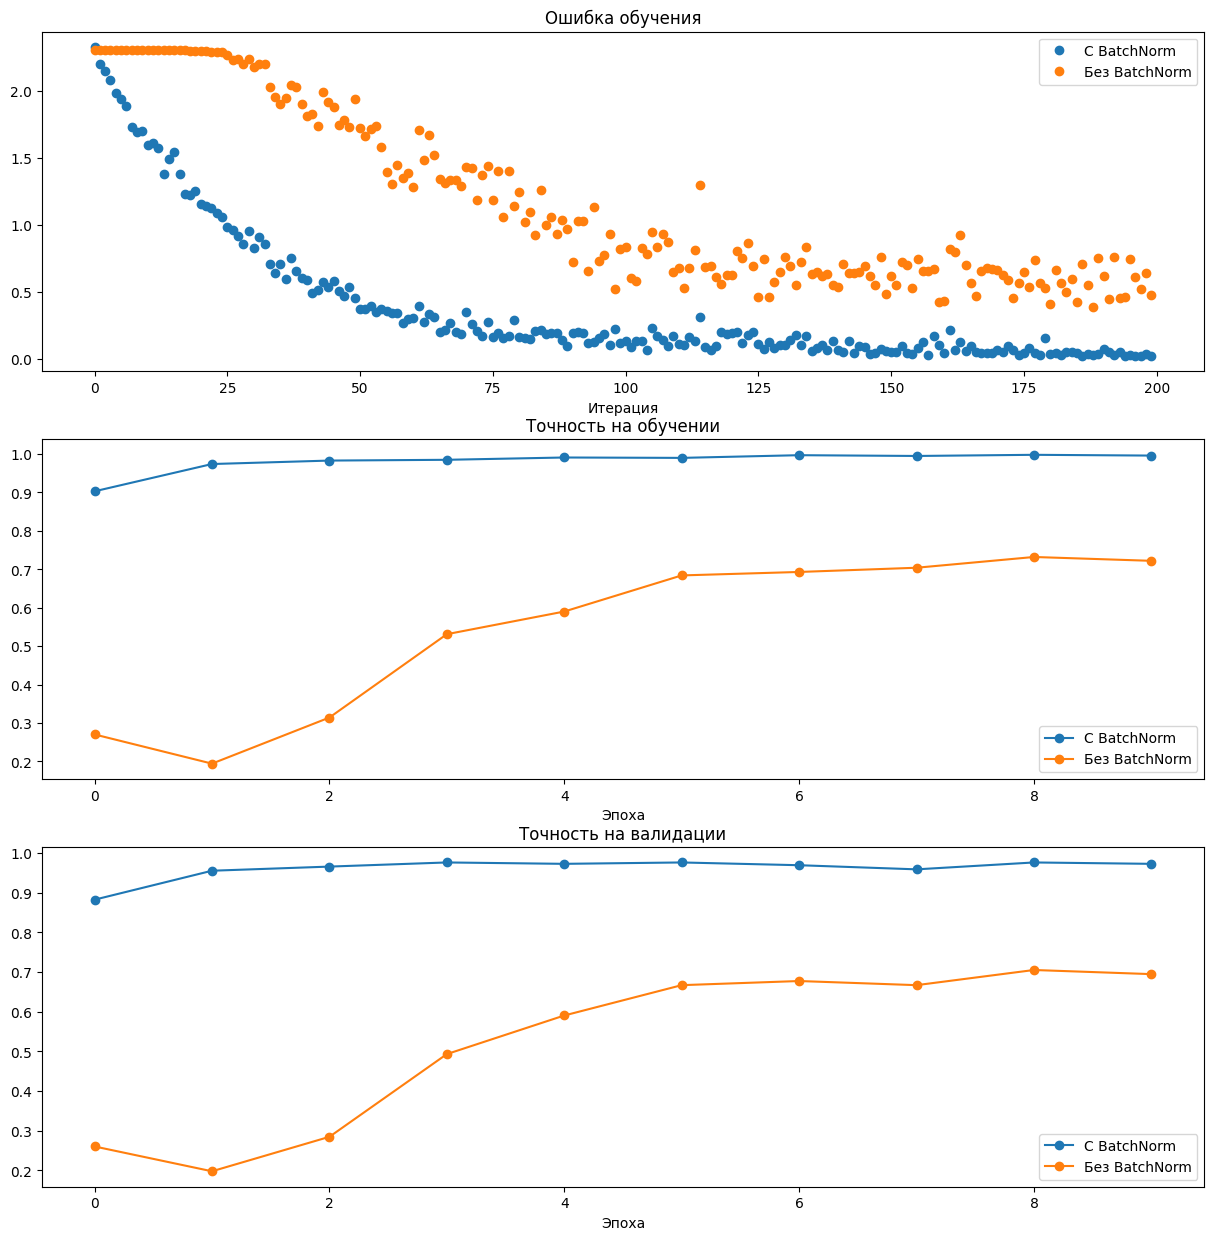

Первая эпоха с точностью ≥90%:
С BatchNorm: 2
Без BatchNorm: None


Вывод: лучшая точность на валидации с BatchNorm — 97.57%, без неё — 70.49%. Сходимость сравнивается по кривым и эпохе достижения 90%; результат относится к этой инициализации и набору Digits.

In [25]:
def plot_training_history(title, label, baseline, bn_solvers, plot_fn,
                          bl_marker='.', bn_marker='.', labels=None):
    plt.title(title)
    plt.xlabel(label)
    for i, current in enumerate(bn_solvers):
        name = 'С BatchNorm'
        if labels is not None:
            name += f', батч={labels[i]}'
        plt.plot(plot_fn(current), bn_marker, label=name)
    name = 'Без BatchNorm'
    if labels is not None:
        name += f', батч={labels[0]}'
    plt.plot(plot_fn(baseline), bl_marker, label=name)
    plt.legend()

plt.subplot(3, 1, 1)
plot_training_history('Ошибка обучения', 'Итерация', solver, [bn_solver],
                      lambda s: s.loss_history, bl_marker='o', bn_marker='o')
plt.subplot(3, 1, 2)
plot_training_history('Точность на обучении', 'Эпоха', solver, [bn_solver],
                      lambda s: s.train_acc_history, bl_marker='-o', bn_marker='-o')
plt.subplot(3, 1, 3)
plot_training_history('Точность на валидации', 'Эпоха', solver, [bn_solver],
                      lambda s: s.val_acc_history, bl_marker='-o', bn_marker='-o')
plt.gcf().set_size_inches(15, 15)
plt.show()

def first_epoch_at(solver, level=0.9):
    return next((i + 1 for i, score in enumerate(solver.val_acc_history) if score >= level), None)

print('Первая эпоха с точностью ≥90%:')
print('С BatchNorm:', first_epoch_at(bn_solver))
print('Без BatchNorm:', first_epoch_at(solver))
display(Markdown(f'Вывод: лучшая точность на валидации с BatchNorm — {bn_solver.best_val_acc:.2%}, '
                 f'без неё — {solver.best_val_acc:.2%}. Сходимость сравнивается по кривым и эпохе '
                 'достижения 90%; результат относится к этой инициализации и набору Digits.'))

Обучите 6-тислойную сеть с батч-нормализацией и без нее, используя разные размеры батча. Визуализируйте графики обучения. Сделайте выводы по результатам эксперимента. 

In [26]:
def run_batchsize_experiments(normalization_mode):
    batch_sizes = [5, 10, 50]
    solvers_by_size = {}
    for batch_size in batch_sizes:
        np.random.seed(42)
        model = FullyConnectedNet([100, 100, 100, 100, 100], input_dim=input_dim,
                                  weight_scale=2e-2, normalization=normalization_mode)
        current = Solver(model, small_data, num_epochs=10, batch_size=batch_size,
                         update_rule='adam', optim_config={'learning_rate': 10**(-3.5)})
        current.train()
        solvers_by_size[batch_size] = current
        print(f'Нормализация={normalization_mode}, батч={batch_size}, '
              f'лучшая точность на валидации={current.best_val_acc:.4f}')
    return solvers_by_size

batch_sizes = [5, 10, 50]
bn_solvers_bsize = run_batchsize_experiments('batchnorm')
solvers_bsize = run_batchsize_experiments(None)

Нормализация=batchnorm, батч=5, лучшая точность на валидации=0.9688


Нормализация=batchnorm, батч=10, лучшая точность на валидации=0.9722


Нормализация=batchnorm, батч=50, лучшая точность на валидации=0.9826


Нормализация=None, батч=5, лучшая точность на валидации=0.9097


Нормализация=None, батч=10, лучшая точность на валидации=0.8889
Нормализация=None, батч=50, лучшая точность на валидации=0.7014


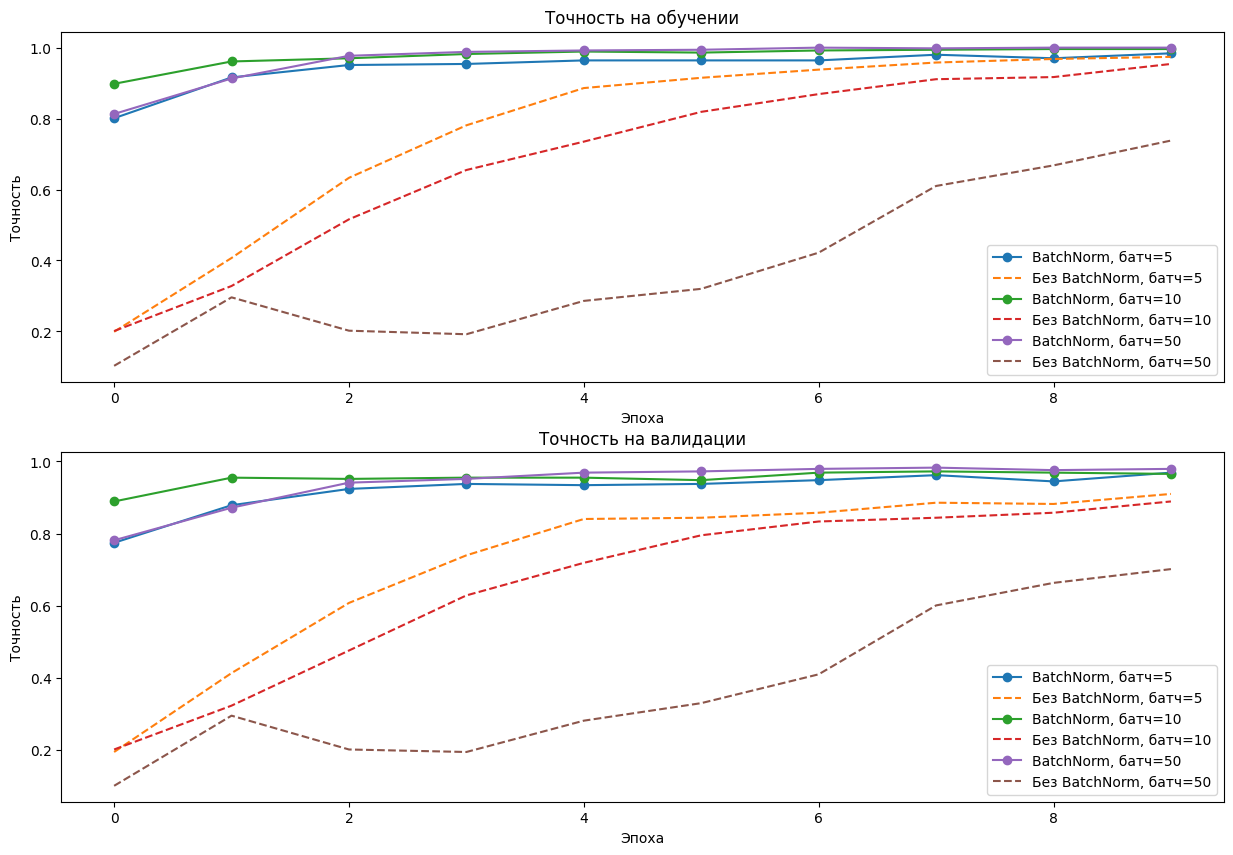

Вывод: среди моделей с BatchNorm лучшая валидационная точность получена при размере батча 50. Малые батчи дают более шумную статистику нормализации, но больше обновлений за эпоху. Поэтому одинаковое число эпох не означает одинаковое число шагов оптимизации.

In [27]:
for panel, (field, title) in enumerate([
    ('train_acc_history', 'Точность на обучении'),
    ('val_acc_history', 'Точность на валидации'),
], start=1):
    plt.subplot(2, 1, panel)
    for batch_size in batch_sizes:
        plt.plot(bn_solvers_bsize[batch_size].__dict__[field], '-o',
                 label=f'BatchNorm, батч={batch_size}')
        plt.plot(solvers_bsize[batch_size].__dict__[field], '--',
                 label=f'Без BatchNorm, батч={batch_size}')
    plt.title(title)
    plt.xlabel('Эпоха')
    plt.ylabel('Точность')
    plt.legend()
plt.gcf().set_size_inches(15, 10)
plt.show()
best_batch = max(batch_sizes, key=lambda b: bn_solvers_bsize[b].best_val_acc)
display(Markdown(f'Вывод: среди моделей с BatchNorm лучшая валидационная точность получена '
                 f'при размере батча {best_batch}. Малые батчи дают более шумную статистику '
                 'нормализации, но больше обновлений за эпоху. Поэтому одинаковое число эпох '
                 'не означает одинаковое число шагов оптимизации.'))

# Dropout

Реализуйте прямой проход для dropout-слоя в scripts/layers.py

http://cs231n.github.io/neural-networks-2/#reg

In [28]:
np.random.seed(231)
x = np.random.randn(500, 500) + 10
for p in [0.25, 0.4, 0.7]:
    out, _ = dropout_forward(x, {'mode': 'train', 'p': p})
    out_test, _ = dropout_forward(x, {'mode': 'test', 'p': p})
    print('Вероятность сохранения нейрона:', p)
    print('Среднее входа:', x.mean())
    print('Среднее выхода при обучении:', out.mean())
    print('Среднее выхода при тестировании:', out_test.mean())
    print('Доля нулей при обучении:', (out == 0).mean())
    print('Доля нулей при тестировании:', (out_test == 0).mean())
    assert np.array_equal(out_test, x)
    assert abs((out == 0).mean() - (1 - p)) < 0.01
    print()

Вероятность сохранения нейрона: 0.25
Среднее входа: 10.0002078784775
Среднее выхода при обучении: 10.014059116977283
Среднее выхода при тестировании: 10.0002078784775
Доля нулей при обучении: 0.749784
Доля нулей при тестировании: 0.0

Вероятность сохранения нейрона: 0.4
Среднее входа: 10.0002078784775
Среднее выхода при обучении: 9.977917658761159
Среднее выхода при тестировании: 10.0002078784775
Доля нулей при обучении: 0.600796
Доля нулей при тестировании: 0.0

Вероятность сохранения нейрона: 0.7
Среднее входа: 10.0002078784775
Среднее выхода при обучении: 9.987811912159428
Среднее выхода при тестировании: 10.0002078784775
Доля нулей при обучении: 0.30074
Доля нулей при тестировании: 0.0



Реализуйте обратный проход для dropout-слоя

In [29]:
np.random.seed(231)
x = np.random.randn(10, 10) + 10
dout = np.random.randn(*x.shape)
dropout_param = {'mode': 'train', 'p': 0.2, 'seed': 123}
out, cache = dropout_forward(x, dropout_param)
dx = dropout_backward(dout, cache)
dx_num = eval_numerical_gradient_array(lambda xx: dropout_forward(xx, dropout_param)[0], x, dout)
verify('dropout_backward dx', dx, dx_num)

dropout_backward dx: 5.45e-11


5.4456084347523126e-11

Добавьте в реализацию класса FullyConnectedNet поддержку dropout. Если параметр dropout != 1, то добавьте в модель dropout-слой после каждого слоя активации. Проверьте свою реализацию

In [30]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=N)
for dropout in [1, 0.75, 0.5]:
    model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                              weight_scale=5e-2, dtype=np.float64, dropout=dropout, seed=123)
    loss, grads = model.loss(X, y)
    print(f'Вероятность сохранения: {dropout}; начальная ошибка: {loss:.6f}')
    for name in sorted(grads):
        grad_num = eval_numerical_gradient(lambda _: model.loss(X, y)[0], model.params[name], verbose=False, h=1e-5)
        verify(f'FC+Dropout p={dropout} {name}', grads[name], grad_num, 1e-4)

Вероятность сохранения: 1; начальная ошибка: 2.300479
FC+Dropout p=1 W1: 1.48e-07
FC+Dropout p=1 W2: 2.21e-05


FC+Dropout p=1 W3: 3.53e-07
FC+Dropout p=1 b1: 5.38e-09
FC+Dropout p=1 b2: 2.09e-09
FC+Dropout p=1 b3: 5.80e-11
Вероятность сохранения: 0.75; начальная ошибка: 2.298773


FC+Dropout p=0.75 W1: 2.73e-07


FC+Dropout p=0.75 W2: 8.82e-07


FC+Dropout p=0.75 W3: 2.94e-08
FC+Dropout p=0.75 b1: 2.39e-08
FC+Dropout p=0.75 b2: 1.01e-08
FC+Dropout p=0.75 b3: 1.34e-10
Вероятность сохранения: 0.5; начальная ошибка: 2.294462
FC+Dropout p=0.5 W1: 4.96e-08


FC+Dropout p=0.5 W2: 9.51e-09
FC+Dropout p=0.5 W3: 2.54e-08
FC+Dropout p=0.5 b1: 6.92e-09
FC+Dropout p=0.5 b2: 4.10e-10
FC+Dropout p=0.5 b3: 1.02e-10


Обучите две двухслойные сети с dropout-слоем (вероятность отсева 0,25) и без на наборе из 500 изображений. Визуализируйте графики обучения. Сделайте выводы по результатам эксперимента

In [31]:
num_train = 500
small_data = {
    'X_train': data['X_train'][:num_train], 'y_train': data['y_train'][:num_train],
    'X_val': data['X_val'], 'y_val': data['y_val'],
}
solvers = {}
# В реализации p — вероятность сохранения: отсев 0.25 соответствует p=0.75.
dropout_choices = [1, 0.75]
for dropout in dropout_choices:
    np.random.seed(42)
    model = FullyConnectedNet([500], input_dim=input_dim, dropout=dropout)
    solver = Solver(model, small_data, num_epochs=25, batch_size=100, update_rule='adam',
                    optim_config={'learning_rate': 5e-4})
    solver.train()
    solvers[dropout] = solver
    print(f'p={dropout}, лучшая точность на валидации={solver.best_val_acc:.4f}')

p=1, лучшая точность на валидации=0.9444
p=0.75, лучшая точность на валидации=0.9479


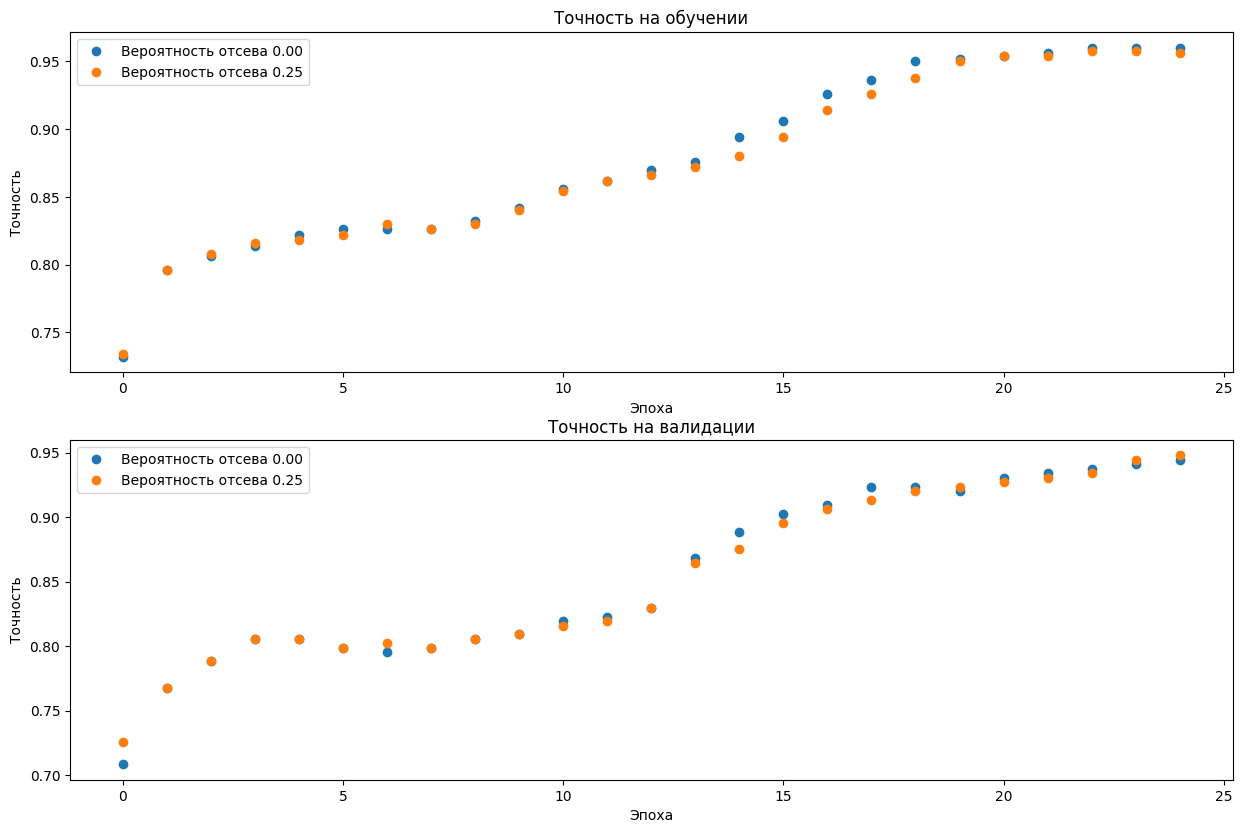

Вывод: лучшая валидационная точность без Dropout — 94.44%, с отсевом 25% — 94.79%. Dropout изменяет обучение, но не гарантирует улучшения в каждом запуске. При проверке и предсказании отсев отключён.

In [32]:
train_accs = [solvers[p].train_acc_history[-1] for p in dropout_choices]
val_accs = [solvers[p].val_acc_history[-1] for p in dropout_choices]
plt.subplot(3, 1, 1)
for p in dropout_choices:
    plt.plot(solvers[p].train_acc_history, 'o', label=f'Вероятность отсева {1-p:.2f}')
plt.title('Точность на обучении')
plt.xlabel('Эпоха')
plt.ylabel('Точность')
plt.legend()
plt.subplot(3, 1, 2)
for p in dropout_choices:
    plt.plot(solvers[p].val_acc_history, 'o', label=f'Вероятность отсева {1-p:.2f}')
plt.title('Точность на валидации')
plt.xlabel('Эпоха')
plt.ylabel('Точность')
plt.legend()
plt.gcf().set_size_inches(15, 15)
plt.show()
display(Markdown(f'Вывод: лучшая валидационная точность без Dropout — '
                 f'{solvers[1].best_val_acc:.2%}, с отсевом 25% — {solvers[0.75].best_val_acc:.2%}. '
                 'Dropout изменяет обучение, но не гарантирует улучшения в каждом запуске. '
                 'При проверке и предсказании отсев отключён.'))

# Сверточные нейронные сети (CNN)

Реализуйте прямой проход для сверточного слоя - функция conv_forward_naive в scripts/layers.py юПроверьте свою реализацию, запустив код ниже 

In [33]:
x_shape = (2, 3, 4, 4)
w_shape = (3, 3, 4, 4)
x = np.linspace(-0.1, 0.5, num=np.prod(x_shape)).reshape(x_shape)
w = np.linspace(-0.2, 0.3, num=np.prod(w_shape)).reshape(w_shape)
b = np.linspace(-0.1, 0.2, num=3)
conv_param = {'stride': 2, 'pad': 1}
out, _ = conv_forward_naive(x, w, b, conv_param)
correct_out = np.array([
    [[[-0.08759809, -0.10987781], [-0.18387192, -0.2109216]],
     [[0.21027089, 0.21661097], [0.22847626, 0.23004637]],
     [[0.50813986, 0.54309974], [0.64082444, 0.67101435]]],
    [[[-0.98053589, -1.03143541], [-1.19128892, -1.24695841]],
     [[0.69108355, 0.66880383], [0.59480972, 0.56776003]],
     [[2.36270298, 2.36904306], [2.38090835, 2.38247847]]]])
verify('conv_forward_naive', out, correct_out)

conv_forward_naive: 2.21e-08


2.2121476417505994e-08

Реализуйте обратный проход - функция conv_backward_naive в scripts/layers.py

In [34]:
np.random.seed(231)
x = np.random.randn(4, 3, 5, 5)
w = np.random.randn(2, 3, 3, 3)
b = np.random.randn(2)
dout = np.random.randn(4, 2, 5, 5)
conv_param = {'stride': 1, 'pad': 1}
dx_num = eval_numerical_gradient_array(lambda x: conv_forward_naive(x, w, b, conv_param)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: conv_forward_naive(x, w, b, conv_param)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: conv_forward_naive(x, w, b, conv_param)[0], b, dout)
out, cache = conv_forward_naive(x, w, b, conv_param)
dx, dw, db = conv_backward_naive(dout, cache)
verify('conv_backward_naive dx', dx, dx_num)
verify('conv_backward_naive dw', dw, dw_num)
verify('conv_backward_naive db', db, db_num)

conv_backward_naive dx: 1.16e-08
conv_backward_naive dw: 2.25e-10
conv_backward_naive db: 3.37e-11


3.37264006649648e-11

Реализуйте прямой проход для max-pooling слоя -функция  max_pool_forward_naive в scripts/layers.py

In [35]:
x_shape = (2, 3, 4, 4)
x = np.linspace(-0.3, 0.4, num=np.prod(x_shape)).reshape(x_shape)
pool_param = {'pool_width': 2, 'pool_height': 2, 'stride': 2}
out, _ = max_pool_forward_naive(x, pool_param)
correct_out = np.array([
    [[[-0.26315789, -0.24842105], [-0.20421053, -0.18947368]],
     [[-0.14526316, -0.13052632], [-0.08631579, -0.07157895]],
     [[-0.02736842, -0.01263158], [0.03157895, 0.04631579]]],
    [[[0.09052632, 0.10526316], [0.14947368, 0.16421053]],
     [[0.20842105, 0.22315789], [0.26736842, 0.28210526]],
     [[0.32631579, 0.34105263], [0.38526316, 0.4]]]])
verify('max_pool_forward_naive', out, correct_out)

max_pool_forward_naive: 4.17e-08


4.1666665157267834e-08

Реализуйте обратный проход для max-pooling слоя в max_pool_backward_naive . 

In [36]:
np.random.seed(231)
x = np.random.randn(3, 2, 8, 8)
dout = np.random.randn(3, 2, 4, 4)
pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}
dx_num = eval_numerical_gradient_array(lambda x: max_pool_forward_naive(x, pool_param)[0], x, dout)
out, cache = max_pool_forward_naive(x, pool_param)
dx = max_pool_backward_naive(dout, cache)
verify('max_pool_backward_naive', dx, dx_num)

max_pool_backward_naive: 3.28e-12


3.27562514223145e-12

В скрипте scripts/fast_layers.py представлены быстрые реализации слоев свертки и пуллинга, написанных с использованием  Cython. 

Для компиляции выполните следующую команду в директории scripts

```bash
python setup.py build_ext --inplace
```


Сравните ваши реализации слоев свертки и пуллинга с быстрыми реализациями.

In [37]:
from scripts.fast_layers import conv_forward_fast, conv_backward_fast
from time import time
np.random.seed(231)
x = np.random.randn(100, 3, 31, 31)
w = np.random.randn(25, 3, 3, 3)
b = np.random.randn(25)
dout = np.random.randn(100, 25, 16, 16)
conv_param = {'stride': 2, 'pad': 1}
t0 = time()
out_naive, cache_naive = conv_forward_naive(x, w, b, conv_param)
t1 = time()
out_fast, cache_fast = conv_forward_fast(x, w, b, conv_param)
t2 = time()
print(f'Прямой проход: обычный={t1-t0:.4f} с; быстрый={t2-t1:.4f} с; ускорение={(t1-t0)/(t2-t1):.2f}')
verify('conv_fast forward', out_fast, out_naive)
t0 = time()
dx_naive, dw_naive, db_naive = conv_backward_naive(dout, cache_naive)
t1 = time()
dx_fast, dw_fast, db_fast = conv_backward_fast(dout, cache_fast)
t2 = time()
print(f'Обратный проход: обычный={t1-t0:.4f} с; быстрый={t2-t1:.4f} с; ускорение={(t1-t0)/(t2-t1):.2f}')
verify('conv_fast dx', dx_fast, dx_naive)
verify('conv_fast dw', dw_fast, dw_naive)
verify('conv_fast db', db_fast, db_naive)

Прямой проход: обычный=2.2385 с; быстрый=0.0073 с; ускорение=304.56
conv_fast forward: 4.93e-11


Обратный проход: обычный=2.9515 с; быстрый=0.0053 с; ускорение=559.07
conv_fast dx: 1.95e-11
conv_fast dw: 3.55e-13
conv_fast db: 7.93e-15


7.93233456841198e-15

In [38]:
from scripts.fast_layers import max_pool_forward_fast, max_pool_backward_fast
np.random.seed(231)
x = np.random.randn(100, 3, 32, 32)
dout = np.random.randn(100, 3, 16, 16)
pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}
t0 = time()
out_naive, cache_naive = max_pool_forward_naive(x, pool_param)
t1 = time()
out_fast, cache_fast = max_pool_forward_fast(x, pool_param)
t2 = time()
print(f'Прямой проход: обычный={t1-t0:.4f} с; быстрый={t2-t1:.4f} с; ускорение={(t1-t0)/(t2-t1):.2f}')
verify('pool_fast forward', out_fast, out_naive)
t0 = time()
dx_naive = max_pool_backward_naive(dout, cache_naive)
t1 = time()
dx_fast = max_pool_backward_fast(dout, cache_fast)
t2 = time()
print(f'Обратный проход: обычный={t1-t0:.4f} с; быстрый={t2-t1:.4f} с; ускорение={(t1-t0)/(t2-t1):.2f}')
verify('pool_fast dx', dx_fast, dx_naive)

Прямой проход: обычный=0.1708 с; быстрый=0.0030 с; ускорение=57.81
pool_fast forward: 0.00e+00


Обратный проход: обычный=0.4102 с; быстрый=0.0009 с; ускорение=460.19
pool_fast dx: 0.00e+00


0.0

В layer_utils.py вы можете найти  часто используемые комбинации слоев, используемых в сверточных сетях. Ознакомьтесь с ними и запустите код ниже для проверки их работы

In [39]:
from scripts.layer_utils import conv_relu_pool_forward, conv_relu_pool_backward
np.random.seed(231)
x = np.random.randn(2, 3, 16, 16)
w = np.random.randn(3, 3, 3, 3)
b = np.random.randn(3)
dout = np.random.randn(2, 3, 8, 8)
conv_param = {'stride': 1, 'pad': 1}
pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}
out, cache = conv_relu_pool_forward(x, w, b, conv_param, pool_param)
dx, dw, db = conv_relu_pool_backward(dout, cache)
dx_num = eval_numerical_gradient_array(lambda x: conv_relu_pool_forward(x, w, b, conv_param, pool_param)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: conv_relu_pool_forward(x, w, b, conv_param, pool_param)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: conv_relu_pool_forward(x, w, b, conv_param, pool_param)[0], b, dout)
verify('conv_relu_pool dx', dx, dx_num)
verify('conv_relu_pool dw', dw, dw_num)
verify('conv_relu_pool db', db, db_num)

conv_relu_pool dx: 9.59e-09
conv_relu_pool dw: 5.80e-09
conv_relu_pool db: 3.58e-10


3.57960501324485e-10

In [40]:
from scripts.layer_utils import conv_relu_forward, conv_relu_backward
np.random.seed(231)
x = np.random.randn(2, 3, 8, 8)
w = np.random.randn(3, 3, 3, 3)
b = np.random.randn(3)
dout = np.random.randn(2, 3, 8, 8)
conv_param = {'stride': 1, 'pad': 1}
out, cache = conv_relu_forward(x, w, b, conv_param)
dx, dw, db = conv_relu_backward(dout, cache)
dx_num = eval_numerical_gradient_array(lambda x: conv_relu_forward(x, w, b, conv_param)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: conv_relu_forward(x, w, b, conv_param)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: conv_relu_forward(x, w, b, conv_param)[0], b, dout)
verify('conv_relu dx', dx, dx_num)
verify('conv_relu dw', dw, dw_num)
verify('conv_relu db', db, db_num)

conv_relu dx: 1.52e-09
conv_relu dw: 3.37e-10
conv_relu db: 4.84e-11


4.842373419350264e-11

Напишите реализацию класса ThreeLayerConvNet в scripts/classifiers/cnn.py . Вы можете использовать готовые реализации слоев и их комбинаций.

Проверьте вашу реализацию. Ожидается, что значение функции потерь softmax будет порядка `log(C)` для `C` классов для случая без регуляризации. В случае регуляризации значение функции потерь должно немного возрасти. 

In [41]:
np.random.seed(231)
model = ThreeLayerConvNet()
N = 50
X = np.random.randn(N, 3, 32, 32)
y = np.random.randint(10, size=N)
loss, grads = model.loss(X, y)
print('Начальная ошибка без регуляризации:', loss)
print('Ожидаемое значение log(10):', np.log(10))
assert abs(loss - np.log(10)) < 0.01
model.reg = 0.5
loss_reg, grads = model.loss(X, y)
print('Начальная ошибка с регуляризацией:', loss_reg)
assert loss_reg > loss

Начальная ошибка без регуляризации: 2.302582
Ожидаемое значение log(10): 2.302585092994046


Начальная ошибка с регуляризацией: 2.5082645


Проверьте реализацию обратного прохода

In [42]:
num_inputs = 2
input_dim_cnn = (3, 16, 16)
reg = 0.0
num_classes = 10
np.random.seed(231)
X = np.random.randn(num_inputs, *input_dim_cnn)
y = np.random.randint(num_classes, size=num_inputs)
model = ThreeLayerConvNet(num_filters=3, filter_size=3,
                          input_dim=input_dim_cnn, hidden_dim=7, dtype=np.float64)
loss, grads = model.loss(X, y)
for param_name in sorted(grads):
    param_grad_num = eval_numerical_gradient(
        lambda _: model.loss(X, y)[0], model.params[param_name], verbose=False, h=1e-6)
    verify(f'ThreeLayerConvNet {param_name}', grads[param_name], param_grad_num, 2e-2)

ThreeLayerConvNet W1: 1.38e-04


ThreeLayerConvNet W2: 1.82e-02
ThreeLayerConvNet W3: 3.06e-04
ThreeLayerConvNet b1: 3.48e-05
ThreeLayerConvNet b2: 2.52e-03
ThreeLayerConvNet b3: 7.95e-10


Попробуйте добиться эффекта переобучения. Обучите модель на небольшом наборе данных.Сравните значения accuracy на обучающих данных и на валидационных. Визуализируйте графики обучения 

In [43]:
np.random.seed(42)
num_train = 100
small_data = {
    'X_train': cnn_data['X_train'][:num_train], 'y_train': cnn_data['y_train'][:num_train],
    'X_val': cnn_data['X_val'], 'y_val': cnn_data['y_val'],
}
model = ThreeLayerConvNet(input_dim=(1, 8, 8), num_filters=16, filter_size=3,
                          hidden_dim=64, weight_scale=0.05)
solver = Solver(model, small_data, num_epochs=40, batch_size=50, update_rule='adam',
                optim_config={'learning_rate': 3e-3}, restore_best=False)
solver.train()
small_cnn_solver = solver

In [44]:
print('Точность на малой обучающей выборке:',
      solver.check_accuracy(small_data['X_train'], small_data['y_train']))

Точность на малой обучающей выборке: 0.96


In [45]:
print('Точность на независимой валидационной выборке:',
      solver.check_accuracy(small_data['X_val'], small_data['y_val']))

Точность на независимой валидационной выборке: 0.8784722222222222


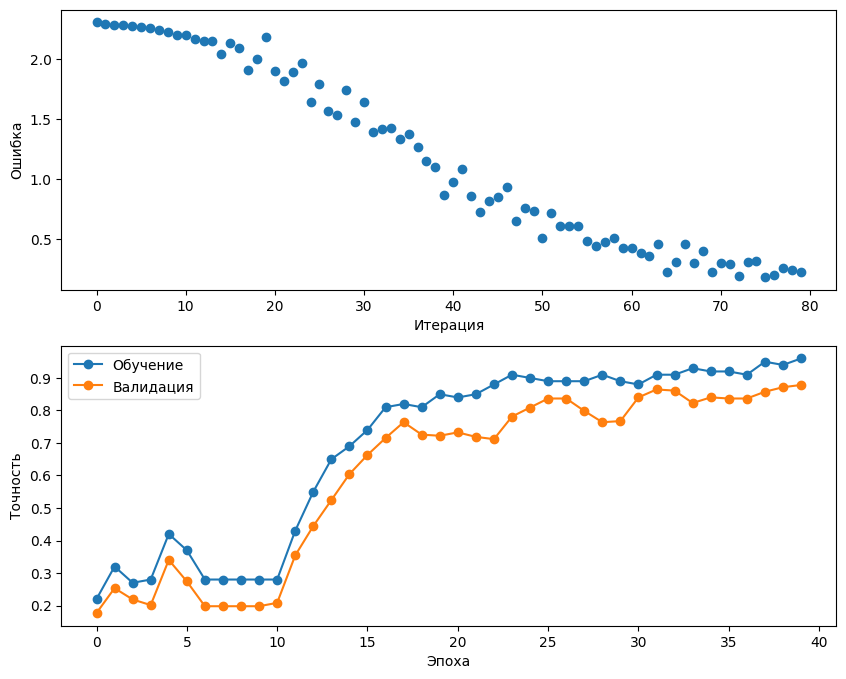

Вывод: сравниваются разные выборки — 100 обучающих изображений и отдельная валидационная часть. Разрыв между их точностями показывает переобучение; совпадение обучающей и валидационной выборок здесь не допускается.

In [46]:
plt.subplot(2, 1, 1)
plt.plot(solver.loss_history, 'o')
plt.xlabel('Итерация')
plt.ylabel('Ошибка')
plt.subplot(2, 1, 2)
plt.plot(solver.train_acc_history, '-o')
plt.plot(solver.val_acc_history, '-o')
plt.legend(['Обучение', 'Валидация'], loc='upper left')
plt.xlabel('Эпоха')
plt.ylabel('Точность')
plt.show()
display(Markdown('Вывод: сравниваются разные выборки — 100 обучающих изображений и отдельная '
                 'валидационная часть. Разрыв между их точностями показывает переобучение; '
                 'совпадение обучающей и валидационной выборок здесь не допускается.'))

Обучите сеть на полном наборе данных. Выведите accuracy на обучающей и валидационной выборках

In [47]:
np.random.seed(42)
model = ThreeLayerConvNet(input_dim=(1, 8, 8), num_filters=16, filter_size=3,
                          hidden_dim=64, weight_scale=0.05, reg=1e-4)
solver = Solver(model, cnn_data, num_epochs=30, batch_size=64, update_rule='adam',
                optim_config={'learning_rate': 1e-3})
solver.train()
best_cnn = model
cnn_solver = solver

In [48]:
print('Точность на всей обучающей выборке:',
      solver.check_accuracy(cnn_data['X_train'], cnn_data['y_train']))

Точность на всей обучающей выборке: 0.9634464751958225


In [49]:
cnn_val_accuracy = float(solver.check_accuracy(cnn_data['X_val'], cnn_data['y_val']))
cnn_test_accuracy = float(solver.check_accuracy(cnn_data['X_test'], cnn_data['y_test']))
print('Точность на валидации:', cnn_val_accuracy)
print('Точность на тесте:', cnn_test_accuracy)

Точность на валидации: 0.9618055555555556
Точность на тесте: 0.9472222222222222


Визуализируйте фильтры на первом слое обученной сети

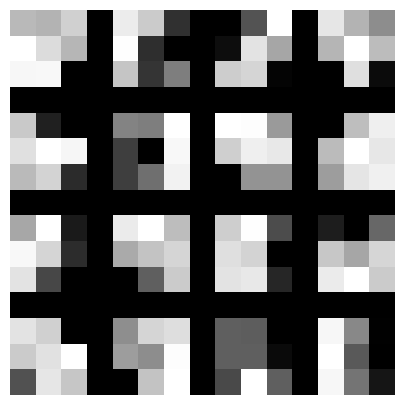

In [50]:
from scripts.vis_utils import visualize_grid
grid = visualize_grid(model.params['W1'].transpose(0, 2, 3, 1))
plt.imshow(grid[..., 0].astype('uint8'))
plt.axis('off')
plt.gcf().set_size_inches(5, 5)
plt.show()

In [51]:
print(f'Полносвязная сеть: валидация={fc_val_accuracy:.4f}, тест={fc_test_accuracy:.4f}')
print(f'CNN: валидация={cnn_val_accuracy:.4f}, тест={cnn_test_accuracy:.4f}')
print('Численных сравнений:', len(checks))
print('Обучающих / валидационных / тестовых изображений:', len(y_train), len(y_val), len(y_test))
display(Markdown('Вывод: реализованы прямой и обратный проходы слоёв и нейросетей, '
                 'оптимизаторы, Batch Normalization, Dropout, свёртка и max-pooling. '
                 'Проверки сравнивают аналитические градиенты с численными и быстрые слои с обычными. '
                 'Данные и разбиение сохранены из исходной пользовательской работы; '
                 'результаты относятся к Digits 8×8, а не к MNIST 28×28 или CIFAR-10.'))

Полносвязная сеть: валидация=0.9931, тест=0.9861
CNN: валидация=0.9618, тест=0.9472
Численных сравнений: 102
Обучающих / валидационных / тестовых изображений: 1149 288 360


Вывод: реализованы прямой и обратный проходы слоёв и нейросетей, оптимизаторы, Batch Normalization, Dropout, свёртка и max-pooling. Проверки сравнивают аналитические градиенты с численными и быстрые слои с обычными. Данные и разбиение сохранены из исходной пользовательской работы; результаты относятся к Digits 8×8, а не к MNIST 28×28 или CIFAR-10.